In [13]:

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
FIG_DIR = ROOT / "paper_figures" / "figure_4"
FIG_DIR.mkdir(parents=True, exist_ok=True)

COLORS = {
    "ink": "#30363A",
    "grid": "#DFE7E5",
}

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9.5,
    "axes.labelsize": 9.5,
    "axes.titlesize": 10,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "axes.linewidth": 0.8,
    "axes.edgecolor": COLORS["ink"],
    "text.color": COLORS["ink"],
    "xtick.color": COLORS["ink"],
    "ytick.color": COLORS["ink"],
    "lines.linewidth": 2.0,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "savefig.transparent": False,
})


def clean_axis(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color=COLORS["grid"], linewidth=0.6)
    ax.tick_params(
        direction="out", length=3, width=0.8,
        colors=COLORS["ink"]
    )


def save_figure(fig, name):
    for ext in ["svg", "pdf", "png"]:
        fig.savefig(
            FIG_DIR / f"{name}.{ext}",
            dpi=300,
            bbox_inches="tight"
        )


## Model comparison

In [14]:

MODEL_DIRS = {
    "Variational (no history)": ROOT / "maze_metric_outputs_no_history",
    "RNN": ROOT / "maze_metric_outputs_rnn",
    "Variational (with history)": ROOT / "maze_metric_outputs_basic",
}

WINDOW = (0.2, 0.3)

MODEL_COLORS = {
    "Variational (no history)": "#8064A2",
    "RNN": "#B66549",
    "Variational (with history)": "#18545D",
}

MODEL_MARKERS = {
    "Variational (no history)": "o",
    "RNN": "s",
    "Variational (with history)": "^",
}

PANEL_SPECS = [
    ("linear_depth_r2", "linear_depth_r2_sem",
     "Linear depth\ndecodability ($R^2$)"),
    ("transition_consistency", "transition_consistency_sem",
     "Local direction\nconsistency"),
    ("tortuosity", "tortuosity_sem",
     "Latent trajectory\ntortuosity"),
]

Y_LIMITS = {
    "linear_depth_r2": (0.35, 1.0),
    "transition_consistency": (0.55, 1.0),
    "tortuosity": (1.0, 5.5),
}


In [15]:

def mean_sem(x):
    x = x.dropna()
    if len(x) < 2:
        return np.nan
    return x.std(ddof=1) / np.sqrt(len(x))


model_data = {}

for model_name, data_dir in MODEL_DIRS.items():
    df = pd.read_csv(
        data_dir / "summary.csv",
        dtype={"seed": str}
    )

    df = df[
        np.isclose(df["window_start"], WINDOW[0])
        & np.isclose(df["window_end"], WINDOW[1])
    ].copy()

    if df.empty:
        raise ValueError(
            f"No data for {model_name} at window {WINDOW}"
        )

    model_data[model_name] = (
        df.groupby("p", as_index=False)
        .agg(
            linear_depth_r2=("linear_depth_r2", "mean"),
            linear_depth_r2_sem=("linear_depth_r2", mean_sem),
            transition_consistency=("transition_consistency", "mean"),
            transition_consistency_sem=("transition_consistency", mean_sem),
            tortuosity=("tortuosity", "mean"),
            tortuosity_sem=("tortuosity", mean_sem),
            n_seeds=("seed", "nunique"),
        )
        .sort_values("p")
        .reset_index(drop=True)
    )

    print(
        f"{model_name}: "
        f"{df['seed'].nunique()} seeds, "
        f"{df['p'].nunique()} p values"
    )


Variational (no history): 15 seeds, 12 p values
RNN: 15 seeds, 11 p values
Variational (with history): 15 seeds, 12 p values


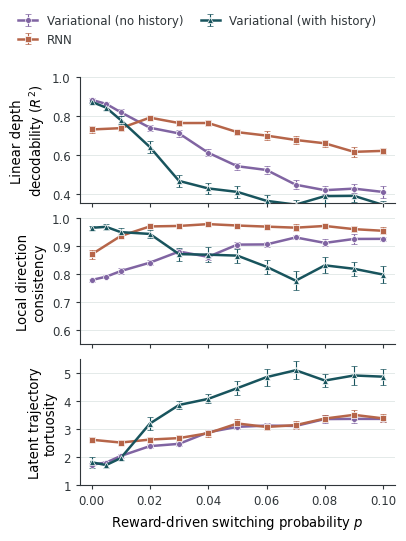

In [16]:

fig, axes = plt.subplots(
    3, 1,
    figsize=(4.2, 5.3),
    sharex=True
)

for ax, (metric, sem_metric, ylabel) in zip(axes, PANEL_SPECS):
    clean_axis(ax)

    for model_name, df in model_data.items():
        ax.errorbar(
            df["p"],
            df[metric],
            yerr=df[sem_metric].fillna(0),
            color=MODEL_COLORS[model_name],
            marker=MODEL_MARKERS[model_name],
            markersize=4.2,
            markeredgecolor="white",
            markeredgewidth=0.5,
            linewidth=1.8,
            elinewidth=0.8,
            capsize=2.0,
            capthick=0.8,
            label=model_name,
            zorder=3,
        )

    ax.set_ylabel(ylabel)
    ax.set_ylim(*Y_LIMITS[metric])
    ax.set_xlim(-0.004, 0.104)
    ax.set_xticks(np.arange(0, 0.101, 0.02))

axes[-1].set_xlabel(
    r"Reward-driven switching probability $p$"
)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=2,
    frameon=False,
    fontsize=8.5,
    handlelength=1.6,
    columnspacing=1.5,
)

fig.subplots_adjust(
    left=0.22,
    right=0.97,
    top=0.87,
    bottom=0.10,
    hspace=0.12
)

save_figure(
    fig,
    f"model_comparison_{WINDOW[0]}_{WINDOW[1]}"
)

plt.show()
plt.close(fig)


## Learning dynamics

In [17]:

DATA_DIR = ROOT / "maze_metric_outputs_basic"

PS = [0.0, 0.01, 0.03, 0.05, 0.1]
SEEDS = [str(i) for i in range(10)]
PROGRESS = list(range(15, 100, 10))

p_vals = np.array(sorted(PS), dtype=float)
norm = mpl.colors.Normalize(vmin=p_vals.min(), vmax=p_vals.max())
cmap = mpl.colormaps["cividis"]

P_COLORS = {
    p: cmap(0.18 + 0.70 * norm(p))
    for p in p_vals
}

P_MARKERS = {
    0.00: "o",
    0.01: "s",
    0.03: "^",
    0.05: "D",
    0.10: "P",
}

DYNAMICS_METRICS = {
    "linear_depth_r2": "Linear depth\ndecodability ($R^2$)",
    "transition_consistency": "Local direction\nconsistency",
    "tortuosity": "Latent trajectory\ntortuosity",
}

fig4_summary = pd.read_csv(
    DATA_DIR / "summary.csv",
    dtype={"seed": str}
)

fig4_summary["progress"] = (
    (fig4_summary["window_start"] + fig4_summary["window_end"]) * 50
).round(4)

fig4_summary = fig4_summary[
    fig4_summary["seed"].isin(SEEDS)
    & fig4_summary["p"].round(6).isin(PS)
    & fig4_summary["progress"].isin(PROGRESS)
].copy()

counts = (
    fig4_summary.groupby(["p", "progress"])["seed"]
    .nunique()
    .unstack()
    .reindex(index=PS, columns=PROGRESS)
)

if counts.isna().any().any():
    raise ValueError("Some p values or training windows are missing.")

display(counts)


progress,15,25,35,45,55,65,75,85,95
p,,,,,,,,,
0.00,10,10,10,10,10,10,10,10,10
0.01,10,10,10,10,10,10,10,10,10
0.03,10,10,10,10,10,10,10,10,10
0.05,10,10,10,10,10,10,10,10,10
0.10,10,10,10,10,10,10,10,10,10


In [18]:

stats_list = []

for metric in DYNAMICS_METRICS:
    stats = (
        fig4_summary
        .groupby(["p", "progress"])[metric]
        .agg(["mean", "sem", "count"])
        .reset_index()
    )

    stats["metric"] = metric
    stats_list.append(stats)

fig4_stats = pd.concat(
    stats_list,
    ignore_index=True
)

fig4_stats.to_csv(
    FIG_DIR / "figure4_mean_sem.csv",
    index=False
)


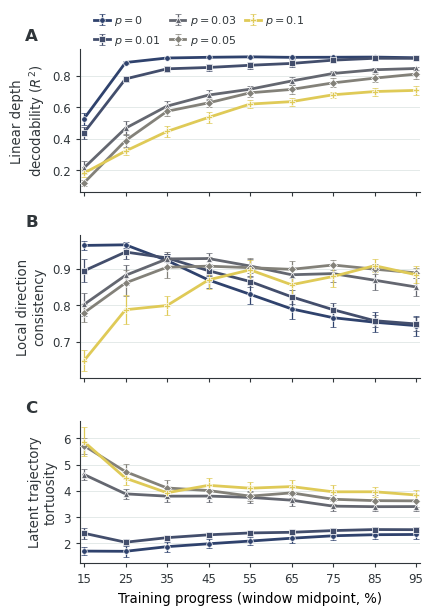

In [19]:

def plot_dynamics(ax, metric, show_xlabel=True):
    clean_axis(ax)

    ax.set_xlim(14, 96)
    ax.set_xticks(np.arange(15, 100, 10))
    ax.margins(x=0.01)

    df = fig4_stats[fig4_stats["metric"] == metric]

    for p in PS:
        d = df[np.isclose(df["p"], p)].sort_values("progress")

        if d.empty:
            continue

        ax.errorbar(
            d["progress"],
            d["mean"],
            yerr=d["sem"].fillna(0),
            color=P_COLORS[p],
            marker=P_MARKERS[p],
            linestyle="-",
            markersize=4.0,
            markeredgecolor="white",
            markeredgewidth=0.5,
            linewidth=2.0,
            elinewidth=0.9,
            capsize=2.0,
            capthick=0.9,
            label=rf"$p={p:g}$",
            zorder=3
        )

    ax.set_ylabel(
        DYNAMICS_METRICS[metric],
        color=COLORS["ink"]
    )

    if show_xlabel:
        ax.set_xlabel("Training progress (window midpoint, %)")
    else:
        ax.tick_params(labelbottom=False)


metrics = list(DYNAMICS_METRICS)
n_panels = len(metrics)

fig, axes = plt.subplots(
    n_panels, 1,
    figsize=(4.6, 1.85 * n_panels + 0.5),
    sharex=True
)

axes = np.atleast_1d(axes)

for i, (ax, metric) in enumerate(zip(axes, metrics)):
    plot_dynamics(
        ax,
        metric,
        show_xlabel=(i == n_panels - 1)
    )

    ax.text(
        -0.16, 1.04,
        chr(65 + i),
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold",
        ha="left",
        va="bottom"
    )

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.995),
    ncol=3,
    frameon=False,
    fontsize=8,
    columnspacing=0.8,
    handlelength=1.4,
    handletextpad=0.4
)

fig.subplots_adjust(
    top=0.92,
    bottom=0.07,
    left=0.24,
    right=0.98,
    hspace=0.30
)

save_figure(fig, "figure4_learning_dynamics")

plt.show()
plt.close(fig)


In [20]:
for name, df in model_data.items():
    print(name, df[["p", "n_seeds"]])

Variational (no history)         p  n_seeds
0   0.000       15
1   0.005       15
2   0.010       15
3   0.020       15
4   0.030       15
5   0.040       15
6   0.050       15
7   0.060       15
8   0.070       15
9   0.080       15
10  0.090       15
11  0.100       15
RNN        p  n_seeds
0   0.00       15
1   0.01       15
2   0.02       15
3   0.03       15
4   0.04       15
5   0.05       15
6   0.06       15
7   0.07       15
8   0.08       15
9   0.09       15
10  0.10       15
Variational (with history)         p  n_seeds
0   0.000       15
1   0.005       15
2   0.010       15
3   0.020       15
4   0.030       15
5   0.040       15
6   0.050       15
7   0.060       15
8   0.070       15
9   0.080       15
10  0.090       15
11  0.100       15
